# 03 · Metric Definitions

**Goal:** agree on what "active", "lost" (churned) and "returning" (reactivated) mean before building any report, and pick the churn threshold from the data rather than by habit.

Reads from `fct_player_week` (notebook 02). Writes `fct_player_week_status` and `ref_week`.

In [1]:
import sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
con = sqlite3.connect(ROOT / "data" / "poker.db")
FIRST_WEEK, LAST_WEEK = "2015-02-02", "2020-06-22"   # full weeks only

def q(sql):
    return pd.read_sql_query(sql, con)

def run(sql):
    con.executescript(sql); con.commit()

## 1. How long do players go between active weeks?

If a player plays, stops, and comes back, how many weeks pass? The churn threshold should be long enough that most players who are coming back have already come back.

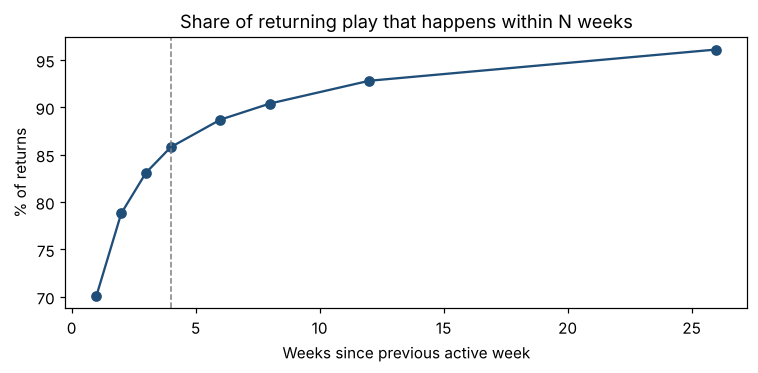

,gap_up_to_weeks,share_of_returns
0,1,0.701
1,2,0.788
2,3,0.831
3,4,0.858
4,6,0.887
5,8,0.904
6,12,0.928
7,26,0.961


In [2]:
gaps = q("""
with w as (select player_id, week_start from fct_player_week where poker_active = 1),
l as (select player_id, week_start,
             lag(week_start) over (partition by player_id order by week_start) as prev_week
      from w)
select cast(round((julianday(week_start) - julianday(prev_week)) / 7) as integer) as gap_weeks
from l where prev_week is not null
""")
thresholds = [1, 2, 3, 4, 6, 8, 12, 26]
coverage = pd.DataFrame({
    "gap_up_to_weeks": thresholds,
    "share_of_returns": [round((gaps.gap_weeks <= k).mean(), 3) for k in thresholds],
})
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(coverage.gap_up_to_weeks, coverage.share_of_returns * 100, marker="o", color="#1f4e79")
ax.axvline(4, color="grey", linestyle="--", linewidth=1)
ax.set_title("Share of returning play that happens within N weeks")
ax.set_xlabel("Weeks since previous active week"); ax.set_ylabel("% of returns")
coverage

There is no sharp elbow: 70% of returns happen the very next week, 86% within 4 weeks, and 90% within 8.

**Decision: a player is churned after 4 consecutive inactive weeks.**

- It captures 86% of returning play, and the curve flattens after this point.
- It is close to the 30-day inactivity rule commonly used in the industry, so the numbers are easy to explain to leadership.
- Players who come back later are not lost: they are counted as **returning players** (reactivated), which is itself a useful growth lever to track.

## 2. Definitions

| Metric | Definition |
|---|---|
| **Weekly active players** | Played at least one cash game or tournament that week |
| **4-week active players** | Played at least once in the last 4 weeks, including the current week (similar to the industry's "28-day actives") |
| **New** | First poker-active week ever |
| **Retained** (stayed) | Active this week and also active within the previous 4 weeks |
| **Returning** (reactivated) | Played this week after more than 4 weeks away |
| **Lost** (churned) | Fourth consecutive inactive week after the last active week; recorded in that fourth week |
| **Net deposits** | Completed deposits minus completed withdrawals (player value proxy; no rake data) |
| **Deposit failure rate** | Failed deposit attempts / all deposit attempts |
| **Withdrawal reversal rate** | Reversed withdrawal value / requested withdrawal value |

These definitions balance exactly from one week to the next, like a bank balance:

> **4-week active players this week = last week's number + new + returning − lost**

## 3. Calendar of full weeks

In [3]:
run(f"""
drop table if exists ref_week;
create table ref_week as
with recursive weeks(week_start) as (
    select date('{FIRST_WEEK}')
    union all
    select date(week_start, '+7 days') from weeks where week_start < '{LAST_WEEK}'
)
select week_start, row_number() over (order by week_start) as week_num from weeks;
""")
q("select count(*) as weeks, min(week_start) as first_week, max(week_start) as last_week from ref_week")

,weeks,first_week,last_week
0,282,2015-02-02,2020-06-22


## 4. Classify every active week and every churn event

In [4]:
run("""
drop table if exists fct_player_week_status;
create table fct_player_week_status as
with active as (
    select f.player_id, r.week_num, r.week_start
    from fct_player_week f join ref_week r on r.week_start = f.week_start
    where f.poker_active = 1
),
seq as (
    select *,
           lag(week_num)  over (partition by player_id order by week_num) as prev_num,
           lead(week_num) over (partition by player_id order by week_num) as next_num
    from active
),
status as (
    select player_id, week_start,
           case when prev_num is null then 'new'
                when week_num - prev_num <= 4 then 'retained'
                else 'reactivated' end as status
    from seq
),
churn as (
    -- churn is recorded in the 4th inactive week, if that week is inside the calendar
    select s.player_id, r.week_start, 'churned' as status
    from seq s join ref_week r on r.week_num = s.week_num + 4
    where s.next_num is null or s.next_num > s.week_num + 4
)
select * from status
union all
select * from churn;
""")
q("select status, count(*) as player_weeks from fct_player_week_status group by 1 order by 2 desc")

,status,player_weeks
0,retained,30100
1,churned,9899
2,reactivated,5007
3,new,4998


Note: players active before the first full week (Sunday 2015-02-01 only) are classified from their first full week. A handful of players whose only activity was on that Sunday never appear here; this is a one-day edge effect.

## 5. QA: does the weekly balance add up every week?

Count the 4-week active players directly, then check that the number equals last week's number plus new plus returning minus lost.

In [5]:
base = q("""
select r.week_start, count(distinct a.player_id) as active_base
from ref_week r
join fct_player_week a
  on a.poker_active = 1
 and a.week_start between date(r.week_start, '-21 days') and r.week_start
 and a.week_start >= '2015-02-02'
group by 1
""")
flows = q("""
select week_start,
       sum(status = 'new') as new_players,
       sum(status = 'reactivated') as reactivated,
       sum(status = 'churned') as churned
from fct_player_week_status group by 1
""")
bridge = q("select week_start from ref_week").merge(base, how="left").merge(flows, how="left").fillna(0)
bridge["implied_base"] = (bridge.new_players + bridge.reactivated - bridge.churned).cumsum()
bridge["difference"] = bridge.active_base - bridge.implied_base
assert (bridge.difference == 0).all(), "Bridge does not hold"
print(f"The weekly balance adds up in all {len(bridge)} weeks.")
bridge.head(6)

The weekly balance adds up in all 282 weeks.


,week_start,active_base,new_players,reactivated,churned,implied_base,difference
0,2015-02-02,875,875,0,0,875,0
1,2015-02-09,1676,801,0,0,1676,0
2,2015-02-16,2472,796,0,0,2472,0
3,2015-02-23,3250,778,0,0,3250,0
4,2015-03-02,3134,228,0,344,3134,0
5,2015-03-09,2762,96,3,471,2762,0


## 6. Sensitivity: how much does the threshold change the story?

In [6]:
rows = []
w = q("""select f.player_id, r.week_num from fct_player_week f join ref_week r on r.week_start = f.week_start
        where f.poker_active = 1""").sort_values(["player_id", "week_num"])
w["gap"] = w.groupby("player_id").week_num.diff()
players = w.player_id.nunique()
for k in [2, 4, 8]:
    react = (w.gap > k).sum()
    rows.append({"threshold_weeks": k,
                 "reactivations": int(react),
                 "reactivations_per_player": round(react / players, 2),
                 "returning_play_counted_as_retained": f"{(w.gap.dropna() <= k).mean():.0%}"})
pd.DataFrame(rows)

,threshold_weeks,reactivations,reactivations_per_player,returning_play_counted_as_retained
0,2,7462,1.49,79%
1,4,5007,1.00,86%
2,8,3360,0.67,90%


A shorter threshold inflates the number of lost and returning players; a longer one delays the churn signal by weeks. Four weeks balances the two. The trend over time does not change with the threshold, only the level.

Definitions are also recorded in `docs/metric_dictionary.md`.

In [7]:
con.close()